# 🌳 Ensemble Learning for Rubber Yield Prediction

**Goal:** predict the **monthly rubber production (Total, MT)** when the user enters a **Year** and a **Month**, and find out **which model is best**.

This notebook trains and compares:

| Group | Models |
|---|---|
| Single models | Random Forest, XGBoost |
| Ensemble models | Voting (RF + XGB), Stacking (RF + XGB → Ridge) |
| Hybrid models | **RF + ARIMA** (time series), **RF + ANN** (tabular regression) |

> The trained models are saved to `artifacts/`.

In [19]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# Split the dataset in time order and tune hyper-parameters without leaking the future
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, KFold

# Models
from sklearn.linear_model import Ridge
from sklearn.ensemble import (RandomForestRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from sklearn.base import clone

warnings.filterwarnings("ignore")
os.makedirs("artifacts/eval", exist_ok=True)
os.makedirs("artifacts/final", exist_ok=True)

## 0. Shared helpers (this cell creates `common.py`)

The cell below contains the shared helper code: the feature engineering, the metrics and the two **hybrid models** (RF + ARIMA, RF + ANN).
Running it **writes the file `common.py`** next to this notebook, and the next cell imports from it.

**Why a file and not just code in the notebook?** The hybrid models are custom classes. If they were defined directly in the notebook, `pickle` would save them as `__main__.RFARIMAHybrid`, and `app.py` (Streamlit) could not load them. Saving them from `common.py` lets `app.py` load the very same classes.

> You only need **this notebook + `app.py`** - the notebook creates `common.py` for you. Keep `common.py` next to `app.py` afterwards.

In [20]:
%%writefile common.py
import warnings

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.arima.model import ARIMA

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
MONTH_TO_NUM = {m: i + 1 for i, m in enumerate(MONTHS)}

# The only inputs a user can give are Year + Month, so these are the model features.
FEATURES = ["Year", "Month_num", "month_sin", "month_cos"]
TARGET = "Total (MT)"
START_YEAR = 2000  # first year in the dataset


def time_index(year, month_num):
    """Months since January 2000 (0, 1, 2, ...). ARIMA needs this to know 'how far ahead'."""
    return (np.asarray(year) - START_YEAR) * 12 + (np.asarray(month_num) - 1)


def build_features(year, month_num):
    """Turn Year + Month number into model features (works for one value or many)."""
    year = np.atleast_1d(year)
    month_num = np.atleast_1d(month_num)
    return pd.DataFrame({
        "Year": year,
        "Month_num": month_num,
        # sin/cos let the model know December is next to January (seasonality)
        "month_sin": np.sin(2 * np.pi * month_num / 12),
        "month_cos": np.cos(2 * np.pi * month_num / 12),
    })


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
    }


class RFARIMAHybrid(BaseEstimator, RegressorMixin):

    def __init__(self, order=(1, 1, 1), n_estimators=200, random_state=42):
        self.order = order
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        t = time_index(X["Year"], X["Month_num"])
        order_idx = np.argsort(t)
        y_sorted = np.asarray(y, dtype=float)[order_idx]
        self.last_t_ = int(t.max())
        self.first_t_ = int(t.min())

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.arima_ = ARIMA(y_sorted, order=self.order, trend="t" if self.order[1] == 1 else "c").fit()

        self.arima_in_sample_ = np.asarray(self.arima_.fittedvalues)
        # ARIMA with differencing has a meaningless first fitted value -> use the real value there
        self.arima_in_sample_[0] = y_sorted[0]

        residual = y_sorted - self.arima_in_sample_
        self.rf_ = RandomForestRegressor(n_estimators=self.n_estimators, random_state=self.random_state, n_jobs=-1)
        self.rf_.fit(X.iloc[order_idx], residual)
        return self

    def _arima_part(self, t):
        t = np.asarray(t)
        out = np.zeros(len(t), dtype=float)
        inside = t <= self.last_t_
        out[inside] = self.arima_in_sample_[t[inside] - self.first_t_]
        if (~inside).any():
            steps = int(t[~inside].max() - self.last_t_)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fc = np.asarray(self.arima_.forecast(steps=steps))
            out[~inside] = fc[t[~inside] - self.last_t_ - 1]
        return out

    def predict(self, X):
        t = time_index(X["Year"], X["Month_num"]).astype(int)
        return self._arima_part(t) + self.rf_.predict(X)


class RFANNHybrid(BaseEstimator, RegressorMixin):
    """
    Hybrid for TABULAR regression:  ANN learns the smooth overall pattern, Random Forest fixes the residuals.
        prediction = ANN(main pattern) + RandomForest(residual part)
    """

    def __init__(self, hidden_layer_sizes=(32, 16), n_estimators=200, random_state=42):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        ann = MLPRegressor(hidden_layer_sizes=self.hidden_layer_sizes, max_iter=3000,
                           random_state=self.random_state)
        self.ann_ = TransformedTargetRegressor(
            regressor=make_pipeline(StandardScaler(), ann), transformer=StandardScaler())
        self.ann_.fit(X, y)
        residual = y - self.ann_.predict(X)
        self.rf_ = RandomForestRegressor(n_estimators=self.n_estimators, random_state=self.random_state, n_jobs=-1)
        self.rf_.fit(X, residual)
        return self

    def predict(self, X):
        return self.ann_.predict(X) + self.rf_.predict(X)

Writing common.py


In [21]:
import importlib, sys
importlib.invalidate_caches()
if "common" in sys.modules:              # re-running the notebook: pick up the freshly written file
    importlib.reload(sys.modules["common"])

# Shared helpers (feature engineering, metrics and the two hybrid models) - written to common.py by the cell above
from common import (MONTH_TO_NUM, MONTHS, FEATURES, TARGET, build_features,
                    regression_metrics, RFARIMAHybrid, RFANNHybrid)

## 1. Load the dataset

In [22]:
file_path = 'data/Dataset_of_Rubber.xlsx'

rubber = pd.read_excel(file_path)

print("Shape:", rubber.shape)
display(rubber.head())

Shape: (288, 10)


,Year,Month,Sheet,Sole,Crepe,Scrap,Crepe Latex,Crepe T.S.R.,Latex,Total (MT)
0,2000,January,4120,245,358,1289,312,2125,0,8449
1,2000,February,4135,247,362,1296,314,2138,0,8492
2,2000,March,4150,249,366,1303,316,2151,0,8535
3,2000,April,4165,251,370,1310,318,2164,0,8578
4,2000,May,4180,253,374,1317,320,2177,0,8621


## 2. Data quality checks

In [23]:
print("Dtypes:\n", rubber.dtypes)
print("\nMissing Values:\n", rubber.isnull().sum())
print("\nDuplicate rows:", int(rubber.duplicated().sum()))
print("\nYears covered:", rubber['Year'].min(), "-", rubber['Year'].max())
print("Rows per year (should be 12):", rubber.groupby('Year').size().unique())
print("\nMonth names:", rubber['Month'].unique().tolist())

# The 'Latex' column is always 0 -> no information
print("\nUnique values in 'Latex':", rubber['Latex'].unique())

display(rubber[TARGET].describe())

Dtypes:
 Year            int64
Month             str
Sheet           int64
Sole            int64
Crepe           int64
Scrap           int64
Crepe Latex     int64
Crepe T.S.R.    int64
Latex           int64
Total (MT)      int64
dtype: object

Missing Values:
 Year            0
Month           0
Sheet           0
Sole            0
Crepe           0
Scrap           0
Crepe Latex     0
Crepe T.S.R.    0
Latex           0
Total (MT)      0
dtype: int64

Duplicate rows: 0

Years covered: 2000 - 2023
Rows per year (should be 12): [12]

Month names: ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

Unique values in 'Latex': [0]


count      288.000000
mean      9273.902778
std        874.932008
min       7630.000000
25%       8397.250000
50%       9805.500000
75%       9974.000000
max      10165.000000
Name: Total (MT), dtype: float64

> ⚠️ **Note on the columns**
>
> * The **target** is `Total (MT)`.
> * The product columns (Sheet, Sole, Crepe, Scrap, ...) are **not used as features**: a user who enters only a *Year* and a *Month* does not know them, and using them would leak the answer.
> * So the model inputs are only **Year** and **Month**.

## 3. Data preprocessing

In [24]:
df = rubber.copy()

# 3.1 Remove duplicates and rows with a missing target (none here, but kept so the notebook works for new data)
df = df.drop_duplicates()
df = df.dropna(subset=['Year', 'Month', TARGET])

# 3.2 Convert month names ("January") to month numbers (1..12)
df['Month_num'] = df['Month'].map(MONTH_TO_NUM)
assert df['Month_num'].notna().all(), "Unknown month name found"

# 3.3 Sort in time order - IMPORTANT for time-series data
df = df.sort_values(['Year', 'Month_num']).reset_index(drop=True)

# 3.4 Feature engineering: Year, Month_num + sin/cos of the month so December is "close" to January
X = build_features(df['Year'].values, df['Month_num'].values)
y = df[TARGET]

# 3.5 Create a date column only for plotting
df['Date'] = pd.to_datetime(dict(year=df['Year'], month=df['Month_num'], day=1))

print("Features used:", FEATURES)
display(X.head())

Features used: ['Year', 'Month_num', 'month_sin', 'month_cos']


,Year,Month_num,month_sin,month_cos
0,2000,1,0.500000,8.660254e-01
1,2000,2,0.866025,5.000000e-01
2,2000,3,1.000000,6.123234e-17
3,2000,4,0.866025,-5.000000e-01
4,2000,5,0.500000,-8.660254e-01


## 4. Exploratory data analysis

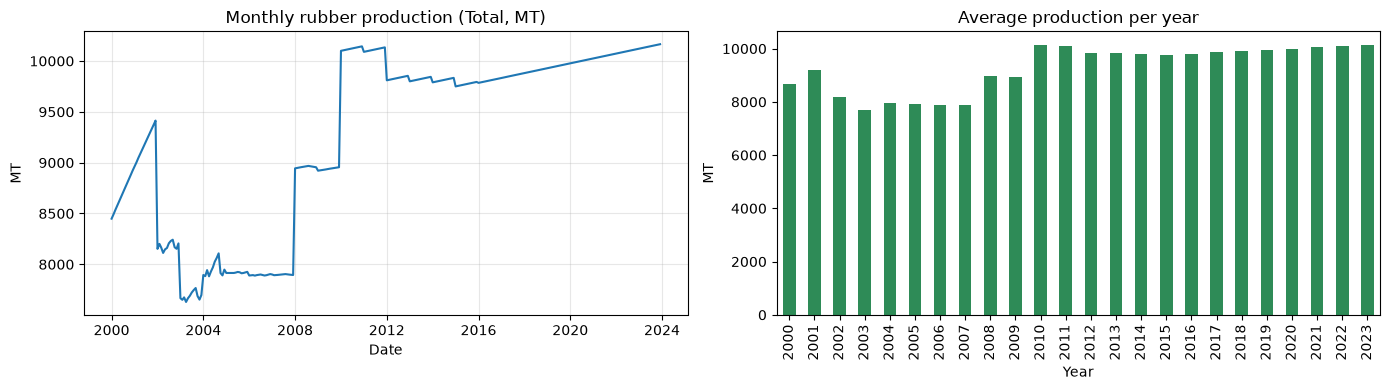

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(df['Date'], y)
ax[0].set_title('Monthly rubber production (Total, MT)')
ax[0].set_xlabel('Date'); ax[0].set_ylabel('MT'); ax[0].grid(alpha=0.3)

df.groupby('Year')[TARGET].mean().plot(kind='bar', ax=ax[1], color='seagreen')
ax[1].set_title('Average production per year')
ax[1].set_ylabel('MT')

plt.tight_layout(); plt.show()

> 📈 The series has **long-term level shifts** (e.g. 2009 → 2010) and a **steady rise within most years**.
> Because the future will lie *beyond* the training years, we split the data **by time**, not randomly.

## 5. Train / Validation / Test split (chronological)

| Set | Years | Purpose |
|---|---|---|
| Train | 2000 – 2017 | learn the model |
| Validation | 2018 – 2020 | tune hyper-parameters / early stopping |
| Test | 2021 – 2023 | final, unseen evaluation |

A random split would let the model "see" months from the future, which is not how forecasting works.

In [26]:
train_mask = df['Year'] <= 2017
val_mask   = (df['Year'] >= 2018) & (df['Year'] <= 2020)
test_mask  = df['Year'] >= 2021

X_train, y_train = X[train_mask], y[train_mask]
X_val,   y_val   = X[val_mask],   y[val_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

# Train + Validation together ("development" data) is used to fit the final models for the test evaluation
dev_mask = train_mask | val_mask
X_dev, y_dev = X[dev_mask], y[dev_mask]

print("Training set  :", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set      :", X_test.shape)

Training set  : (216, 4)
Validation set: (36, 4)
Test set      : (36, 4)


## 6. Hyper-parameter tuning (using only training / validation data)

The test set is **never** touched in this section.

### 6.1 Random Forest - grid search with time-series cross-validation

In [27]:
# TimeSeriesSplit always trains on the past and validates on the future
tscv = TimeSeriesSplit(n_splits=3)

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid={
        'n_estimators': [100, 300],        # number of trees
        'max_depth': [None, 5, 10],        # deeper trees fit more detail but may overfit
        'min_samples_leaf': [1, 3],        # bigger leaves make the model smoother
    },
    cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1
)
rf_grid.fit(X_train, y_train)

best_rf_params = rf_grid.best_params_
print("Best RF params:", best_rf_params)
print("CV RMSE:", round(-rf_grid.best_score_, 2))

Best RF params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
CV RMSE: 480.72


### 6.2 XGBoost - early stopping on the validation set

Best number of trees: 440


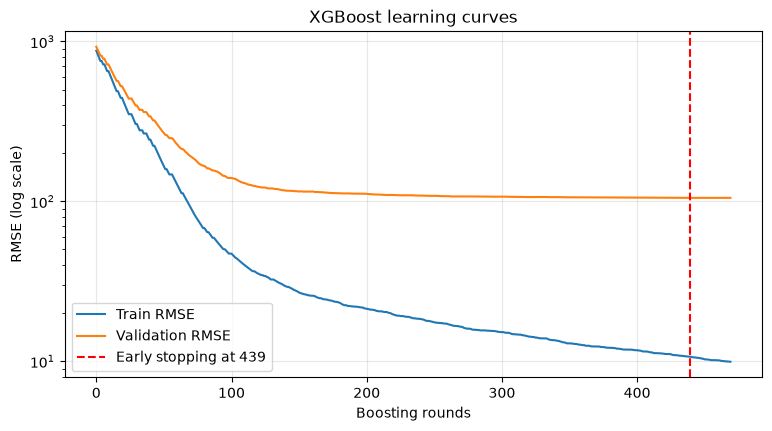

In [28]:
# eval_set lets XGBoost measure the error after every tree.
# Training stops when the validation error has not improved for 30 rounds.
xgb_es = XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=3,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric='rmse', early_stopping_rounds=30,
    random_state=42, n_jobs=-1
)
xgb_es.fit(X_train, y_train,
           eval_set=[(X_train, y_train), (X_val, y_val)],
           verbose=False)

curves = xgb_es.evals_result()
best_xgb_rounds = int(xgb_es.best_iteration) + 1
print("Best number of trees:", best_xgb_rounds)

plt.figure(figsize=(9, 4.5))
plt.plot(curves['validation_0']['rmse'], label='Train RMSE')
plt.plot(curves['validation_1']['rmse'], label='Validation RMSE')
plt.axvline(xgb_es.best_iteration, color='red', linestyle='--', label=f'Early stopping at {xgb_es.best_iteration}')
plt.yscale('log'); plt.xlabel('Boosting rounds'); plt.ylabel('RMSE (log scale)')
plt.title('XGBoost learning curves'); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 6.3 Hybrid models - choose the ARIMA order and the ANN size on the validation set

In [29]:
# ---- RF + ARIMA: try a few ARIMA orders (p, d, q)
arima_scores = {}
for order in [(1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 2)]:
    m = RFARIMAHybrid(order=order).fit(X_train, y_train)
    arima_scores[order] = regression_metrics(y_val, m.predict(X_val))['RMSE']
print("RF + ARIMA validation RMSE:", {k: round(v, 1) for k, v in arima_scores.items()})
best_arima_order = min(arima_scores, key=arima_scores.get)
print("Best ARIMA order:", best_arima_order)

# ---- RF + ANN: try a few network sizes
ann_scores = {}
for layers in [(16,), (32, 16), (64, 32)]:
    m = RFANNHybrid(hidden_layer_sizes=layers).fit(X_train, y_train)
    ann_scores[layers] = regression_metrics(y_val, m.predict(X_val))['RMSE']
print("\nRF + ANN validation RMSE:", {k: round(v, 1) for k, v in ann_scores.items()})
best_ann_layers = min(ann_scores, key=ann_scores.get)
print("Best ANN layers:", best_ann_layers)

RF + ARIMA validation RMSE: {(1, 1, 0): 53.2, (0, 1, 1): 53.3, (1, 1, 1): 53.3, (2, 1, 2): 62.5}
Best ARIMA order: (1, 1, 0)

RF + ANN validation RMSE: {(16,): 192.5, (32, 16): 94.3, (64, 32): 133.8}
Best ANN layers: (32, 16)


## 7. Build all models

All models are created by one function so that the **same settings** are used for the test evaluation, the cross-validation and the final model.

In [30]:
def make_models():
    rf  = RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1)
    xgb = XGBRegressor(n_estimators=best_xgb_rounds, learning_rate=0.05, max_depth=3,
                       subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)

    # Voting: every model predicts, the average is the answer
    voting = VotingRegressor([('rf', rf), ('xgb', xgb)])

    # Stacking: a Ridge model learns how to combine the predictions of RF and XGB.
    # KFold WITHOUT shuffling keeps the folds as consecutive blocks of time.
    stacking = StackingRegressor(
        estimators=[('rf', rf), ('xgb', xgb)],
        final_estimator=Ridge(alpha=1.0),
        cv=KFold(n_splits=5, shuffle=False)
    )

    return {
        'random_forest':     rf,
        'xgboost':           xgb,
        'voting':            voting,
        'stacking':          stacking,
        'hybrid_rf_arima':   RFARIMAHybrid(order=best_arima_order, random_state=42),
        'hybrid_rf_ann':     RFANNHybrid(hidden_layer_sizes=best_ann_layers, random_state=42),
    }

DISPLAY_NAMES = {
    'random_forest':     'Random Forest',
    'xgboost':           'XGBoost',
    'voting':            'Voting (RF+XGB)',
    'stacking':          'Stacking (RF+XGB)',
    'hybrid_rf_arima':   'Hybrid RF + ARIMA',
    'hybrid_rf_ann':     'Hybrid RF + ANN',
}
GROUPS = {
    'random_forest': 'Single',
    'xgboost': 'Single', 'voting': 'Ensemble', 'stacking': 'Ensemble',
    'hybrid_rf_arima': 'Hybrid', 'hybrid_rf_ann': 'Hybrid',
}
print(list(make_models().keys()))

['random_forest', 'xgboost', 'voting', 'stacking', 'hybrid_rf_arima', 'hybrid_rf_ann']


## 8. Train the models and evaluate on the test set

Models are trained on **Train + Validation (2000-2020)** and tested on **2021-2023**.

In [31]:
eval_models = make_models()
test_pred = {}
rows = []

for name, model in eval_models.items():
    model.fit(X_dev, y_dev)
    test_pred[name] = model.predict(X_test)
    rows.append({'Model': DISPLAY_NAMES[name], 'Group': GROUPS[name],
                 **regression_metrics(y_test, test_pred[name])})

results = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
print("✅ All models trained.\n")
display(results.round(3))

✅ All models trained.



,Model,Group,MAE,RMSE,R2,MAPE
0,Hybrid RF + ANN,Hybrid,33.683,39.146,0.112,0.333
1,Stacking (RF+XGB),Ensemble,35.234,40.425,0.054,0.349
2,Hybrid RF + ARIMA,Hybrid,39.583,46.022,-0.227,0.391
3,Random Forest,Single,96.413,104.087,-5.275,0.954
4,Voting (RF+XGB),Ensemble,97.077,104.697,-5.348,0.960
5,XGBoost,Single,97.741,105.315,-5.424,0.967


> ℹ️ **About R²:** the 2021-2023 production values lie in a very narrow range (≈10,025 - 10,165 MT), so the variance of the test set is tiny and R² becomes strongly negative for *every* model.
> Use **MAE / RMSE / MAPE** (error in MT or %) to compare the models; R² is shown only for completeness.

## 9. Actual vs predicted (test set)

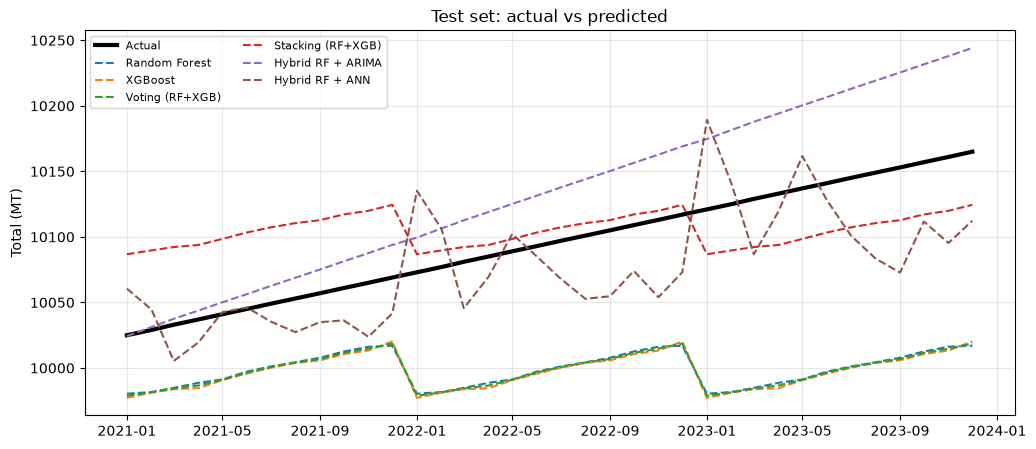

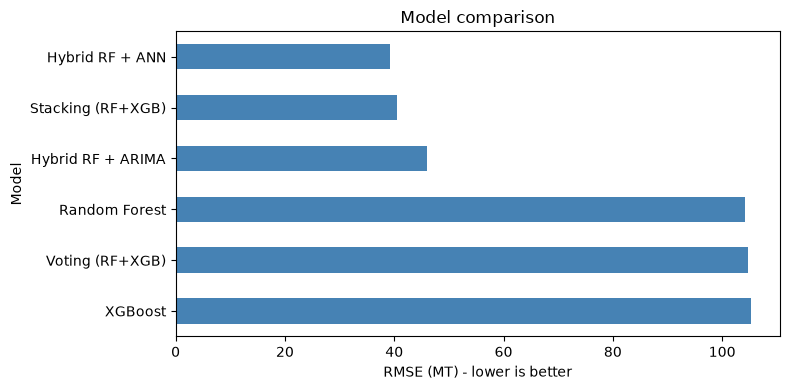

In [32]:
dates_test = df.loc[test_mask, 'Date']

plt.figure(figsize=(12, 5))
plt.plot(dates_test, y_test.values, color='black', linewidth=3, label='Actual')
for name, p in test_pred.items():
    plt.plot(dates_test, p, linestyle='--', label=DISPLAY_NAMES[name])
plt.title('Test set: actual vs predicted'); plt.ylabel('Total (MT)')
plt.legend(ncol=2, fontsize=8); plt.grid(alpha=0.3); plt.show()

# Bar chart of the errors
results.plot(x='Model', y='RMSE', kind='barh', legend=False, color='steelblue', figsize=(8, 4))
plt.gca().invert_yaxis(); plt.xlabel('RMSE (MT) - lower is better'); plt.title('Model comparison'); plt.tight_layout(); plt.show()

## 10. Walk-forward cross-validation (robustness check)

One test window can be lucky or unlucky. Here every model is trained on the past and tested on the next 24 months, **5 times** (the window moves forward each time).

In [33]:
wf = TimeSeriesSplit(n_splits=5, test_size=24)
cv_rows = {name: [] for name in make_models()}

for fold, (tr_idx, te_idx) in enumerate(wf.split(X), start=1):
    for name, model in make_models().items():
        m = clone(model).fit(X.iloc[tr_idx], y.iloc[tr_idx])
        cv_rows[name].append(regression_metrics(y.iloc[te_idx], m.predict(X.iloc[te_idx])))

cv_results = []
for name, folds in cv_rows.items():
    cv_results.append({
        'model': name, 'name': DISPLAY_NAMES[name], 'group': GROUPS[name],
        'RMSE_mean': float(np.mean([f['RMSE'] for f in folds])),
        'RMSE_std':  float(np.std([f['RMSE'] for f in folds])),
        'MAE_mean':  float(np.mean([f['MAE'] for f in folds])),
        'MAPE_mean': float(np.mean([f['MAPE'] for f in folds])),
        'RMSE_per_fold': [f['RMSE'] for f in folds],
    })

cv_df = pd.DataFrame(cv_results).sort_values('RMSE_mean')[['name', 'group', 'RMSE_mean', 'RMSE_std', 'MAE_mean', 'MAPE_mean']]
display(cv_df.round(2).reset_index(drop=True))

,name,group,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean
0,Hybrid RF + ARIMA,Hybrid,62.65,51.67,55.57,0.56
1,Random Forest,Single,66.04,15.29,61.59,0.62
2,Voting (RF+XGB),Ensemble,66.20,15.47,61.76,0.62
3,XGBoost,Single,66.37,15.67,61.93,0.62
4,Hybrid RF + ANN,Hybrid,69.13,40.28,59.87,0.61
5,Stacking (RF+XGB),Ensemble,71.24,31.59,66.43,0.67


## 11. Feature importance (tree-based models)

,Random Forest,XGBoost
Year,0.997,0.977
Month_num,0.002,0.009
month_sin,0.001,0.009
month_cos,0.000,0.005


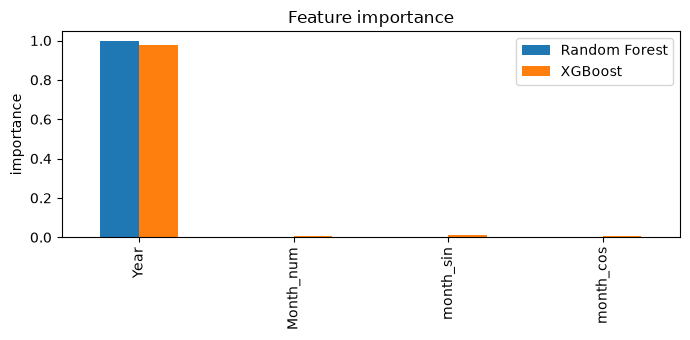

In [34]:
imp = pd.DataFrame({
    'Random Forest': eval_models['random_forest'].feature_importances_,
    'XGBoost':       eval_models['xgboost'].feature_importances_,
}, index=FEATURES)
display(imp.round(3))
imp.plot(kind='bar', figsize=(7, 3.5)); plt.title('Feature importance'); plt.ylabel('importance'); plt.tight_layout(); plt.show()

## 12. Retrain on ALL data for forecasting

The final models see every month (2000-2023) so they can forecast **future** months. The test scores above come from the models trained without 2021-2023.

In [35]:
final_models = make_models()
for name, model in final_models.items():
    model.fit(X, y)
print("✅ Final models trained on all", len(X), "rows")

✅ Final models trained on all 288 rows


## 13. Save the models and metadata for the API

In [36]:
for name in eval_models:
    # for fair test comparison (trained on 2000-2020)
    with open(f"artifacts/eval/{name}.pkl", "wb") as f:
        pickle.dump(eval_models[name], f)
    # for future predictions (trained on all data)
    with open(f"artifacts/final/{name}.pkl", "wb") as f:
        pickle.dump(final_models[name], f)

meta = {
    'target': TARGET,
    'features': FEATURES,
    'data_years': [int(df['Year'].min()), int(df['Year'].max())],
    'split': {'train': [2000, 2017], 'validation': [2018, 2020], 'test': [2021, 2023]},
    'models': {n: {'name': DISPLAY_NAMES[n], 'group': GROUPS[n]} for n in eval_models},
    'best_params': {
        'random_forest': {k: v for k, v in best_rf_params.items()},
        'xgboost_trees': best_xgb_rounds,
        'arima_order': list(best_arima_order),
        'ann_layers': list(best_ann_layers),
    },
    'cross_validation': cv_results,
}
with open('artifacts/meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

print("Saved .pkl files:", sorted(os.listdir('artifacts/final')))

Saved .pkl files: ['gradient_boosting.pkl', 'hybrid_rf_ann.pkl', 'hybrid_rf_arima.pkl', 'random_forest.pkl', 'stacking.pkl', 'voting.pkl', 'xgboost.pkl']


## 14. Predict the yield for a given Year and Month

Load the saved models and predict - exactly what the API does when the dashboard sends a year and a month.

In [37]:
loaded = {}
for n in DISPLAY_NAMES:
    with open(f"artifacts/final/{n}.pkl", "rb") as f:
        loaded[n] = pickle.load(f)

def predict_yield(year, month):
    # month can be a name ("June") or a number (6)
    month_num = MONTH_TO_NUM[month] if isinstance(month, str) else int(month)
    features = build_features(year, month_num)
    return {DISPLAY_NAMES[n]: round(float(m.predict(features)[0]), 1) for n, m in loaded.items()}

print("Prediction for June 2025:")
display(pd.Series(predict_yield(2025, "June"), name='Total (MT)').to_frame())

Prediction for June 2025:


,Total (MT)
Random Forest,10141.4
XGBoost,10139.8
Voting (RF+XGB),10140.6
Stacking (RF+XGB),10276.5
Hybrid RF + ARIMA,10270.6
Hybrid RF + ANN,10207.0


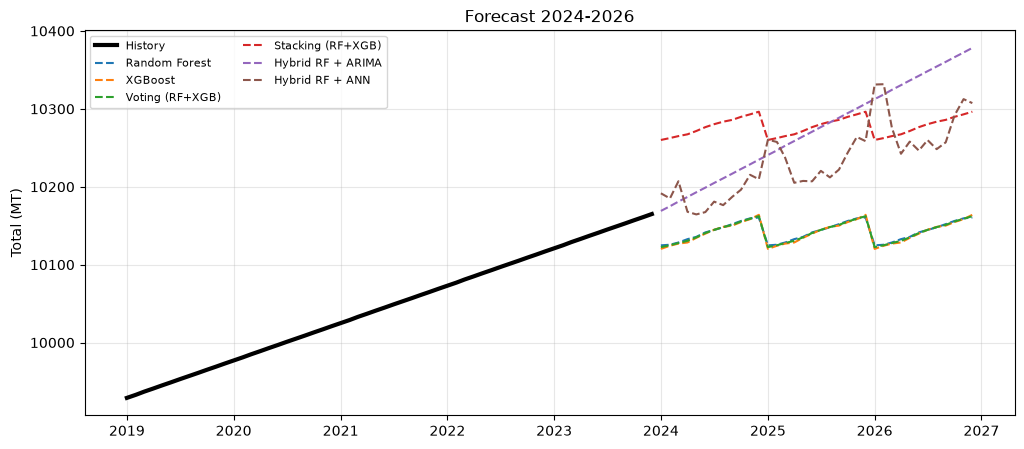

In [38]:
# Forecast chart for the next 3 years (2024-2026)
future = pd.DataFrame([(yr, m) for yr in (2024, 2025, 2026) for m in range(1, 13)], columns=['Year', 'Month_num'])
Xf = build_features(future['Year'].values, future['Month_num'].values)
future_dates = pd.to_datetime(dict(year=future['Year'], month=future['Month_num'], day=1))

plt.figure(figsize=(12, 5))
plt.plot(df['Date'].iloc[-60:], y.iloc[-60:], color='black', linewidth=3, label='History')
for n, m in loaded.items():
    plt.plot(future_dates, m.predict(Xf), linestyle='--', label=DISPLAY_NAMES[n])
plt.title('Forecast 2024-2026'); plt.ylabel('Total (MT)'); plt.legend(ncol=2, fontsize=8); plt.grid(alpha=0.3); plt.show()

## Interpretation

In this project, Hybrid RF + ANN performed the best in the main test set, achieving the lowest RMSE of 39.1 MT. I think it performed well because ANN learns the main production pattern, while Random Forest helps to correct the remaining errors. However, I also used MAE and MAPE because R² alone is not enough to evaluate model performance, especially when actual production values have very little variation. In walk-forward validation, Hybrid RF + ARIMA achieved the lowest average RMSE. Therefore, the best model can depend on the evaluation period.